# a sanity on the values of dbdt

In [3]:
from em1d.experiment import Loop, Receiver, integrate_around_loop
import matplotlib.pyplot as plt
import numpy as np
import torch
twopi = 2*torch.pi
twopi_sqrt = np.sqrt(twopi)

In [20]:
from em1d.physics import calc_wavenumber, mu0
import em1d.transforms as tr

class Forward:
    def __init__(self, source, receiver, times):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)
    
    def forward1(self):
        def frq_integrand1(omega):
            omega = omega[None,:]
            k = calc_wavenumber(self.sigma, omega)
            kr = k*self.r
            intg = (3.-(3.+3j*kr-kr**2)*torch.exp(-1j*kr))/kr**2/self.r**2
            return intg
        f_t=tr.invFourier(frq_integrand1, smp_per_decade=30)
        cbs = tr.CubicSpline(*f_t.range(self.times[0], self.times[-1]), transform=torch.log)
        res = cbs(self.times)
        cbs2 = tr.CubicSpline(torch.squeeze(self.r), res, transform=torch.log)
        resp_of_t = 
        return integrate_around_loop(self.source, self.receiver, cbs2)
    
    def __call__(self, sigma, thick):
        self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
        self.r =  torch.logspace(-1, 2, 51)[:,None]
        return self.forward1()

In [32]:
from em1d.physics import freespace_u0 as u0, refl_transverse_electric as rte
twopi = torch.pi*2

class Forward:
    def __init__(self, source, receiver, times, radius=1.):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)

        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0])

    def forward(self):
        def frq_integrand(omega):
            omega = omega[None,:,None]
            def integrand(wave_length):
                lmb = wave_length[None, None, :]
                k = calc_wavenumber(self.sigma[0], omega, sqrt=False)
                u = torch.sqrt(lmb**2 - k)
                tmp_u0 = u0(omega, lmb)
                crte  = (lmb - u) / (lmb + u)
                intg = torch.squeeze((1.+crte)*lmb**2 / tmp_u0)
                return intg
            
            hkl1 = tr.Hankel(integrand, 1, smp_per_decade=6)
            r, hr = hkl1.range(self.rmin, self.rmax)
            HofR = tr.CubicSpline(r.real, hr, transform=torch.log10)
            HofF = integrate_around_loop(self.source, self.receiver, HofR)
            return torch.squeeze(HofF)
        f_t=tr.invFourier(frq_integrand, smp_per_decade=30)
        t,dbdt = f_t.range(self.times[0], self.times[-1])
        cbs = tr.CubicSpline(t, dbdt)
        return cbs(self.times)

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
        return self.forward()

In [33]:
ainv_dbdt=np.array([2.749861e-04, 1.753167e-04, 1.011688e-04, 6.031561e-05,
       3.650625e-05, 2.059544e-05, 1.194428e-05, 7.079678e-06,
       3.957627e-06, 2.293402e-06, 1.403765e-06, 8.236817e-07,
       4.389777e-07, 2.446409e-07, 1.422868e-07, 7.752075e-08,
       4.302391e-08, 2.479088e-08, 1.362022e-08, 7.621867e-09])

times = np.array([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05,
       3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
       1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
       5.575e-04, 7.035e-04])

In [34]:
side = 40

lp = Loop.square(side)
print(len(lp))
rx=Receiver()

rho = 40
sigma = 1/torch.tensor([rho,rho, rho, rho, rho])
thick = torch.tensor([1, 2, 20, 40])

# fwr = Forward(lp, rx, np.logspace(-6, -1, 61))
fwr = Forward(lp, rx, times)

5


C:\Users\au646858\AppData\Local\Temp\ipykernel_5312\2217116270.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0])


In [35]:
from scipy.special import erf

a = np.sqrt(side*side/np.pi)
fwr = Forward(lp, rx, times)

sgm = (1./rho)
theta = np.sqrt(0.25*mu0*sgm / fwr.times.numpy())
dhdt = 1./(mu0*sgm*a**3)*(3*erf(theta*a)-2*theta*a*(3+2*theta**2*a**2)*np.exp(-theta**2*a**2)/np.sqrt(np.pi))

C:\Users\au646858\AppData\Local\Temp\ipykernel_5312\2217116270.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0])


In [36]:
dbdt = fwr(sigma, thick)
print(dhdt/dbdt.real)

C:\Users\au646858\AppData\Local\Temp\ipykernel_5312\2217116270.py:37: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_5312\2217116270.py:38: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


TypeError: log10(): argument 'input' (position 1) must be Tensor, not float

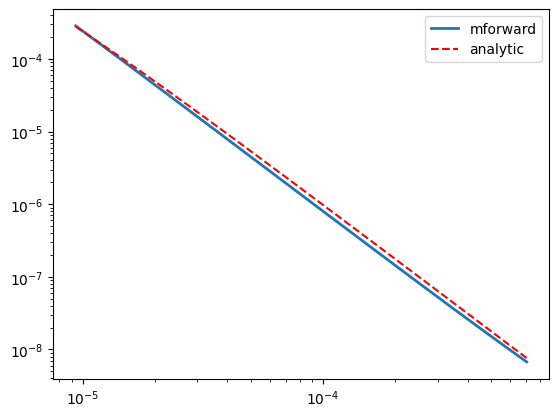

In [31]:
fig,ax = plt.subplots()
ax.loglog(fwr.times.numpy(), mu0*np.abs(dbdt.real), linewidth=2, label='mforward')
# ax.loglog(times,      ainv_dbdt, '--', label='AarhusInv', )
ax.loglog(fwr.times.numpy(),       dhdt*mu0, 'r--', label='analytic')
ax.legend()

In [249]:
def norm(tensor, axis=-1):
    return torch.sqrt(torch.sum(tensor**2, axis=axis))


def getRz(P,Q):
    QP = Q-P
    mQP = norm(QP)
    cos_theta = QP[..., 0] / mQP
    sin_theta = QP[..., 1] / mQP

    Rz = torch.zeros(QP.shape+(3,), device=P.device)

    Rz[..., 0,0] = cos_theta
    Rz[..., 1,1] = cos_theta
    Rz[..., 0,1] = sin_theta
    Rz[..., 1,0] = -sin_theta
    Rz[..., 2,2] = 1.
    
    return Rz, torch.swapaxes(Rz, -1, -2)


def integrate_around_loop(lp, rx, hr):

    lp_xyz = lp.xyz - rx.xyz[None, ...]
    
    HR = torch.zeros((180,)+hr(0.).shape)
    n_dipoles = 0
    wire_length=0
    for i in range(len(lp)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...i,...i->...', Rz, lp_xyz[i])
        p2 = torch.einsum('...i,...i->...', Rz, lp_xyz[i+1])

        p12 = p2-p1
        tdist = norm(p12)
        p12 /= tdist
        cp = p1
        cdist = 0

        while cdist < tdist:
            cR = norm(cp)
            ds = cR/25
            if cdist+ds > tdist:
                ds = tdist-cdist
                cdist += cR/25
            else:
                cdist += ds
            wire_length+=ds
            resp = hr(cR)
            HR[n_dipoles] = ds*cp[1]*resp/cR
            
            cp += ds*p12
            n_dipoles +=1
    print('number of dipoles: ', n_dipoles)
    print('wire length: ', wire_length)
    return HR

In [250]:
from functools import *
def hzdt_hedp(sigma, r, times, YoverR=1.):
    y = YoverR*r
    theta = np.sqrt(0.25*mu0*sigma / times)
    OR = theta*r
    hzdt = (3+2*OR**2)*np.exp(-OR**2)*OR*2/np.sqrt(np.pi)
    hzdt = 3*erf(OR) - hzdt
    hzdt *= y
    hzdt /= 2*np.pi*sigma*mu0*r**5
    return hzdt

def hed_of_R(r):
    return hzdt_hedp(1./40, r, torch.tensor(simpeg_times))

a = np.sqrt(40*40/np.pi)
lp2 = Loop.circle(a, n=100)
dbdt = torch.sum(integrate_around_loop(lp2, rx, hed_of_R), axis=0)

IndexError: index 180 is out of bounds for dimension 0 with size 180

In [228]:
print(2*np.pi*a)

141.79630807244126


RuntimeError: value cannot be converted to type double without overflow

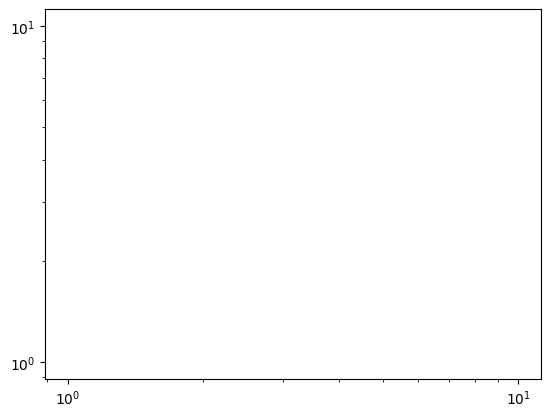

In [229]:
plt.figure()
plt.loglog(times, -dbdt)
plt.loglog(times, ainv_dbdt/mu0)

In [230]:
dbdt=-1*integrate_around_loop(lp, rx, cbs3)*mu0

number of dipoles:  180
wire length:  tensor(160.0000)


In [231]:
simpeg_dbdt = np.array([9.14942871e-03, 7.71086508e-03, 6.15910347e-03, 4.67083236e-03,
       3.37637936e-03, 2.33858123e-03, 1.56082571e-03, 1.00941691e-03,
       6.35817174e-04, 3.91849692e-04, 2.37214231e-04, 1.41527306e-04,
       8.34490020e-05, 4.87387894e-05, 2.82495152e-05, 1.62737497e-05,
       9.32902209e-06, 5.32702044e-06, 3.03232586e-06, 1.72181224e-06,
       9.75740048e-07, 5.52073042e-07, 3.11970243e-07, 1.76114745e-07,
       9.93420411e-08, 5.60010330e-08, 3.15530336e-08, 1.77710676e-08,
       1.00057393e-08, 5.63217472e-09, 3.16968167e-09, 1.78354639e-09,
       1.00345363e-09, 5.64508228e-10, 3.17557036e-10, 1.78637245e-10,
       1.00494262e-10, 5.65388408e-11, 3.18127694e-11, 1.79024128e-11,
       1.00757608e-11, 5.67147395e-12, 3.19269774e-12, 1.79743503e-12,
       1.01197791e-12, 5.69770995e-13, 3.20797666e-13, 1.80615360e-13,
       1.01686780e-13, 5.72470015e-14, 3.22269325e-14])
simpeg_times = np.logspace(-6, -1, 51)

In [232]:
from em1d.physics import hzdt_halfspace_center_circle_loop


In [233]:
dbdt_circle = hzdt_halfspace_center_circle_loop(torch.from_numpy(simpeg_times), 1./40, np.sqrt(40*40/np.pi))

ValueError: x and y must have same first dimension, but have shapes (51,) and (180, 20)

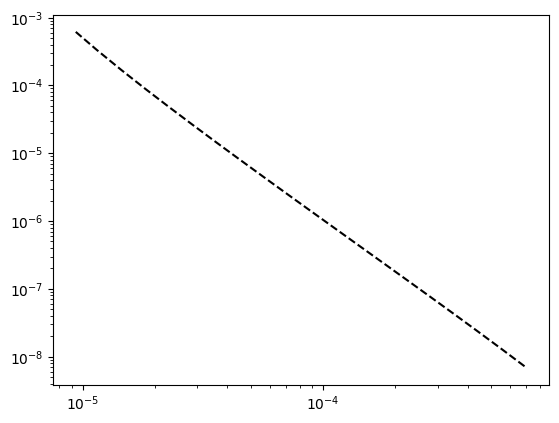

In [234]:
plt.figure()
plt.loglog(times, ainv_dbdt, 'k--', label='aarhusInv')
plt.loglog(simpeg_times, -mu0*dbdt.real.numpy())
# plt.loglog(simpeg_times, simpeg_dbdt, 'r--')
plt.loglog(simpeg_times, mu0*dbdt_circle.numpy())
# plt.loglog(simpeg_times, mu0*simpeg_times**(-5/2))

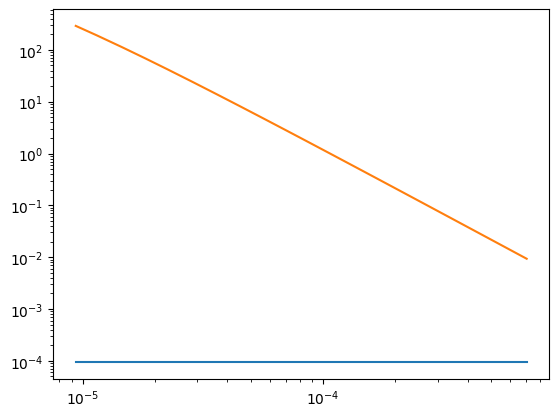

In [64]:
resp1 = -1*cbs2(torch.tensor(a)).numpy()*a*2*np.pi
resp2 = -1*cbs2(torch.tensor(28)).numpy()*28*2*np.pi

plt.figure()
plt.loglog(times, resp1.real)
plt.loglog(times, resp2.real)

In [146]:
from em1d.physics import hzdt_halfspace_center_circle_loop
dhdt = hzdt_halfspace_center_circle_loop(t, 1./40., np.sqrt(40*40/np.pi))

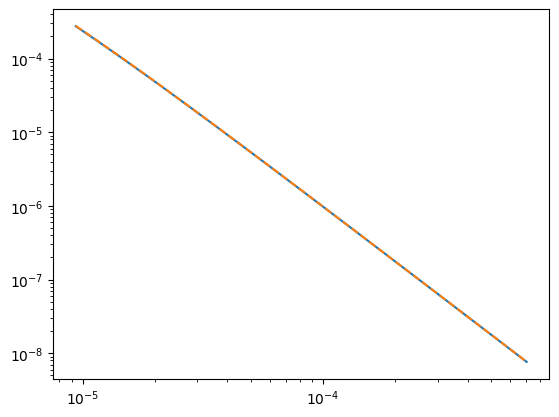

In [147]:
plt.figure()
plt.loglog(times, -mu0*dbdt.real)#resp.real)
plt.loglog(times, mu0*dhdt.numpy().real, '--')
#plt.loglog(times, ainv_dbdt)

c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


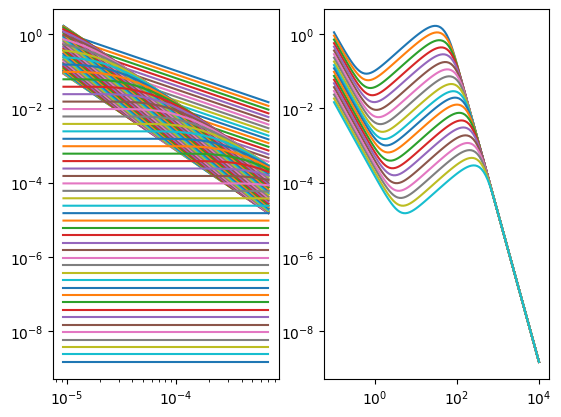

In [87]:
fig,axs = plt.subplots(1,2)

axs[0].loglog(times, -res.numpy().T)
# axs[0].legend(labels=times)
#axs[0].loglog(times, -res.numpy()[1].T)

axs[1].loglog(r.numpy(), -res.numpy())

In [45]:
res.shape

torch.Size([101, 20])

In [107]:
skindepth = np.squeeze(500*np.sqrt(40/np.squeeze(f.numpy())))

c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


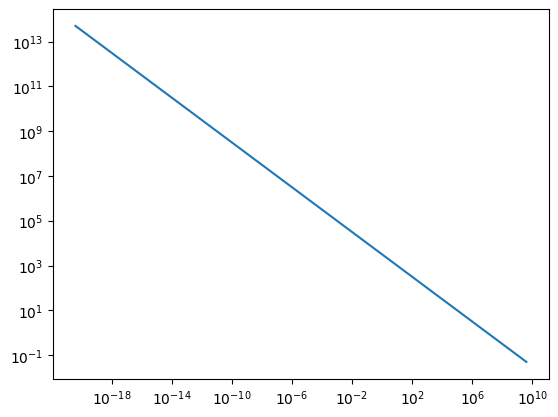

In [110]:
plt.figure()
plt.loglog(np.squeeze(f.numpy()), np.abs(skindepth))

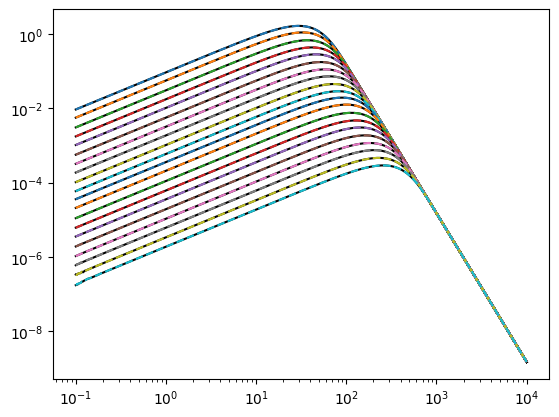

In [124]:
from scipy.special import erf



respgrid1 = np.zeros((len(r),20))

for ir,a in enumerate(r):
    # a = np.sqrt(side*side/np.pi)
    sgm = (1./rho)
    theta = np.sqrt(0.25*mu0*sgm / times)
    dhdt = 1./(mu0*sgm*a**3)*(3*erf(theta*a)-2*theta*a*(3+2*theta**2*a**2)*np.exp(-theta**2*a**2)/np.sqrt(np.pi))
    respgrid1[ir] = dhdt/(2*np.pi*a)

plt.figure()
plt.loglog(r, respgrid1, 'k-')
plt.loglog(r, respgrid, '--')
# plt.loglog(r, r**-4, 'b--')

In [112]:
def hzdt_vmdp(sigma, r, times):
    """ward&hohmann eq4.70 pg215"""
    theta = np.sqrt(0.25*mu0*sigma / times)
    hzdt = 9*erf(theta*r) - (2*theta*r)/np.sqrt(np.pi)*(9+6*theta**2*r**2 + 4*theta**4*r**4)*np.exp(-theta**2*r**2)
    hzdt /= -2*np.pi*mu0*sigma*r**5
    return hzdt

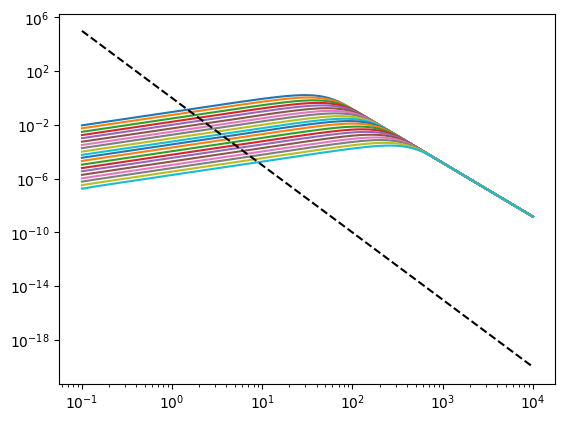

In [121]:
r = np.logspace(-1, 4, 501)
respgrid = hzdt_hedp(1./40, r[:, None], times[None, :])

plt.figure()
plt.loglog(r, np.abs(respgrid))
plt.loglog(r, r**(-5), 'k--')

In [60]:
print(r.shape)
cbs3 = tr.CubicSpline(r[:,0], torch.tensor(respgrid.T))

torch.Size([101, 1])


In [203]:
data = np.genfromtxt(r"P:\matt.griffiths\TxWaveform\20240503-0001_profiler_Tx_waveform_good.csv", delimiter=',', skip_header=4).T

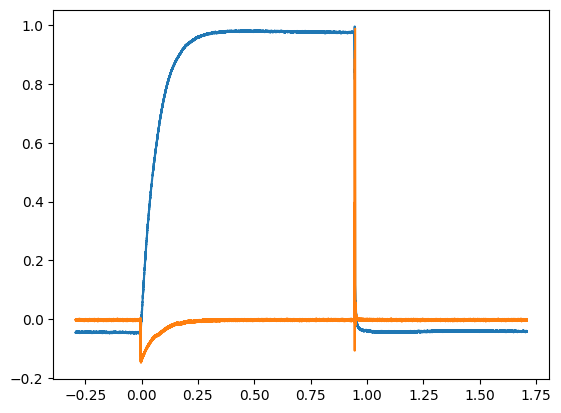

In [205]:
plt.figure()
plt.plot(data[0], data[1])
plt.plot(data[0], data[2])